# DreaMS embeddings and molecular families

**Context.** PRIORITY project (WUR). Meeting with Joana Tirana and Daniel Probst on 19 Oct 2026: embeddings for metabolomics, molecular families, and the DreaMS paper (Bushuiev et al., *Nature Biotechnology*, 2025).
**Author:** Vitória Maia

**Questions.** Do DreaMS embeddings of MS/MS spectra put metabolites of the same molecular family close together? Does DreaMS similarity follow chemical structure better than the modified cosine that GNPS uses, and better than MS2DeepScore? As a first look towards federated learning: how different are the labs, and does a small layer trained across labs help?

**Steps**
0. Check that our DreaMS installation reproduces the numbers of the DreaMS networking tutorial.
1. Take six public GNPS molecular networking jobs on actinobacteria registered in the Paired Omics Data Platform.
2. Keep the spectra that pass DreaMS's own format A check, unchanged (the *protocol* variant). Our earlier cleaning is kept as a sensitivity analysis (*all_kept*).
3. Compute embeddings with the **pre-trained** DreaMS and MS2DeepScore models.
4. **Experiment A:** neighbours and a DreaMS network vs the GNPS molecular families.
5. **Experiment B:** spectral similarities vs structural similarity (Morgan Tanimoto and MHFP) on library-annotated spectra.
6. **Experiment C (prototype):** a small layer on frozen DreaMS embeddings, trained locally, centrally, with FedAvg and SplitFedV2-like, one lab per client.
7. **Experiment D:** can a classifier tell the labs apart from their embeddings?
8. Which public datasets could test DreaMS for genome-metabolome linking?

Each step is a script in `scripts/`. The notebook runs them and shows the results. `RESULTS.md` has the numbers of A and B in one page.

## 0. Setup

**One-time steps** (in a terminal, inside `priority-wur/dreams_molecular_families`). DreaMS and MS2DeepScore pin different package versions, so each gets its own Python 3.11 environment, made with [uv](https://docs.astral.sh/uv/):
```
git clone https://github.com/pluskal-lab/DreaMS.git .DreaMS
git -C .DreaMS checkout dbec3a0b514a99e5056cfccde4559fda8cfe8129
uv venv .dreams_env --python 3.11
uv pip install --python .dreams_env/Scripts/python.exe -e ./.DreaMS mhfp==1.9.6 ipykernel nbclient
uv venv .ms2ds_env --python 3.11
uv pip install --python .ms2ds_env/Scripts/python.exe "ms2deepscore>=2.6" onnxruntime
```
(On Mac/Linux, use `bin/python` instead of `Scripts/python.exe`.) The first runs download the DreaMS weights (2.6 GB, Hugging Face) and the MS2DeepScore model (416 MB, Zenodo). These folders are git-ignored.

**Data.** The GNPS jobs come from `data/raw/gnps/`, which `python -I scripts/download_data.py gnps` fills (run from the repository root).

**Kernel.** Any Jupyter kernel with pandas works: the steps always run with the Python of the right environment.

In [1]:
import importlib.util
import os
import subprocess
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

RUNS = ["duncan_salinispora", "crusemann_salstrep", "crusemann_streptomyces",
        "chevrette_insect", "dorrestein_salbus", "tahlan_streptomyces"]
VARIANTS = ["protocol", "all_kept"]
RESULTS_DIR = {"protocol": "results", "all_kept": "results_all_kept"}

EXPERIMENT_DIR = Path.cwd()
if not (EXPERIMENT_DIR / "scripts" / "common.py").exists():
    raise RuntimeError("Open this notebook from the dreams_molecular_families folder.")


def env_python(name):
    path = EXPERIMENT_DIR / name / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
    if not path.exists():
        raise RuntimeError(f"{name} not found. Do the one-time steps in section 0.")
    return str(path)


# Python used for the steps: this kernel if it has DreaMS, otherwise .dreams_env.
PY = sys.executable if importlib.util.find_spec("dreams") is not None else env_python(".dreams_env")
PY_MS2DS = env_python(".ms2ds_env")
print("DreaMS steps:", PY)
print("MS2DeepScore steps:", PY_MS2DS)


def step(script, *args, python=None, show=False, allow_fail=False):
    # Run one script and stop with its error message if it fails.
    start = time.time()
    result = subprocess.run(
        [python or PY, f"scripts/{script}", *args], capture_output=True, text=True,
        encoding="utf-8", errors="replace", env={**os.environ, "PYTHONUTF8": "1"},
    )
    if result.returncode != 0:
        if allow_fail:
            print(f"skipped: {script} {' '.join(args)}: {result.stdout.strip().splitlines()[-1:] or result.stderr[-300:]}")
            return
        print(result.stdout[-5000:], result.stderr[-5000:], sep="\n")
        raise RuntimeError(f"{script} {' '.join(args)} failed. Read the error above.")
    if show:
        print(result.stdout)
    print(f"done: {script} {' '.join(args)} ({time.time() - start:.0f} s)")


def results(run, name, variant="protocol"):
    return pd.read_parquet(EXPERIMENT_DIR / "runs" / run / RESULTS_DIR[variant] / f"{name}.parquet")


def side_by_side(name, key="metric", value="value", variant="protocol"):
    # One summary table per run, merged into one table with a column per run.
    tables = []
    for run in RUNS:
        path = EXPERIMENT_DIR / "runs" / run / RESULTS_DIR[variant] / f"{name}.parquet"
        if path.exists():
            tables.append(pd.read_parquet(path).set_index(key)[value].rename(run))
    return pd.concat(tables, axis=1).fillna("")


pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 200)

DreaMS steps: C:\Users\iraci\github-Victoria125\priority-wur\dreams_molecular_families\.dreams_env\Scripts\python.exe
MS2DeepScore steps: C:\Users\iraci\github-Victoria125\priority-wur\dreams_molecular_families\.ms2ds_env\Scripts\python.exe


## 0b. Does our DreaMS installation reproduce a published result?

Before comparing DreaMS with other methods, we check our setup against the DreaMS networking tutorial, which the DreaMS authors ran and saved with its outputs. It uses one public file (S_N1.mzML, MassIVE MSV000086206) and reports 3,809 spectra, a DreaMS similarity of 0.9109248 between spectra 1137 and 1165, and 6,858 edges in the DreaMS k-NN network. The script follows the tutorial code exactly, so none of our own processing is involved.

In [2]:
reproduction = EXPERIMENT_DIR / "reproduction" / "dreams_networking_tutorial.json"
if not reproduction.exists():
    step("reproduce_dreams_tutorial.py")
display(pd.read_json(reproduction, typ="series"))

expected (DreaMS tutorial)             {'spectra': 3809, 'pair_similarity': 0.9109248, 'network_edges': 6858}
pair                                                                                             [1137, 1165]
got (this machine)            {'spectra': 3809, 'pair_similarity': 0.9109244999999999, 'network_edges': 6858}
match                                       {'spectra': True, 'pair_similarity': True, 'network_edges': True}
reproduced                                                                                               True
seconds                                                                                                  1896
dreams_commit                                                        dbec3a0b514a99e5056cfccde4559fda8cfe8129
computed_on                                                                               2026-11-09T17:02:21
dtype: object

## 1. Data and the two versions of the input spectra

| Run | Dataset | MassIVE (PoDP) | GNPS fragment tolerance |
|---|---|---|---|
| `duncan_salinispora` | *Salinispora*, Duncan et al. 2015 (ion trap). Example job of the NPLinker docs | MSV000079284 | 0.3 Da |
| `crusemann_salstrep` | *Salinispora* + *Streptomyces*, Crüsemann et al. 2017 | MSV000078836 | 0.5 Da |
| `crusemann_streptomyces` | *Streptomyces*, Crüsemann et al. 2017 | MSV000078839 | 0.5 Da |
| `chevrette_insect` | Insect-associated actinobacteria, Chevrette et al. 2019 | MSV000084723 | 0.02 Da |
| `dorrestein_salbus` | *Streptomyces albus* J1074, Dorrestein lab | MSV000079519 | 0.01 Da |
| `tahlan_streptomyces` | Clavulanic acid producing *Streptomyces*, Tahlan lab | MSV000083835 | 0.02 Da |

All are GNPS jobs that the Paired Omics Data Platform links to genomes. The two Crüsemann jobs overlap: the SalStrep job also re-analyses MSV000078839.

**Molecular families.** GNPS connects two spectra when their modified cosine is high enough. Each connected group is a molecular family (`componentindex`). Spectra without connections are singletons.

**Checks.** `prepare_data.py` stops if the spectra with peaks are not exactly the network nodes, or if edges or library hits point to unknown nodes.

**Two versions of the input spectra.**
- `protocol` (main): only the spectra that pass DreaMS's own format A check (`DataFormatA().val_spec`: charge +1, precursor and fragments at most m/z 1000, 3 to 128 peaks, at least 3 peaks above 10% intensity, max/min intensity at least 20), given to every method exactly as GNPS gives them.
- `all_kept` (sensitivity analysis): our first cleaning. It removes the peaks above the precursor *before* applying the same rules, so it also keeps spectra that DreaMS's own check rejects: old ion trap data in the Duncan job (fragments heavier than the precursor, which is noise), and noise above m/z 1000 in every spectrum of the Crüsemann *Streptomyces* job. That job has no `protocol` spectra.

In [3]:
for run in RUNS:
    step("prepare_data.py", "--run", run)

info = pd.DataFrame({run: pd.read_json(EXPERIMENT_DIR / "runs" / run / "results" / "run_info.json", typ="series") for run in RUNS})
display(info.drop([i for i in info.index if "md5" in i or i == "run"]))
display(side_by_side("00_filter_report", key="step", value="spectra"))

done: prepare_data.py --run duncan_salinispora (11 s)


done: prepare_data.py --run crusemann_salstrep (11 s)


done: prepare_data.py --run crusemann_streptomyces (13 s)


done: prepare_data.py --run chevrette_insect (7 s)


done: prepare_data.py --run dorrestein_salbus (7 s)


done: prepare_data.py --run tahlan_streptomyces (9 s)


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
GNPS edges between these spectra (all_kept),289,4329,1695,1075,2670,8067
GNPS edges between these spectra (protocol),88,3902,NaN,903,2655,8047
GNPS families (size >= 2) (all_kept),20,299,148,100,193,1029
GNPS families (size >= 2) (protocol),13,282,NaN,97,193,1027
GNPS network edges,397,6750,2542,1644,4393,12521
GNPS task,c22f44b14a3d450eb836d607cb9521bb,9360fa514804487a9d39b7e7d7e6d514,840eadb054f74d74ae42152a08ed9628,927974dc1fe640d081b1467464815efa,7e463ca89a7c41958a0d0b993ee52131,b5eb34985777438aaf0f87e31889384c
GNPS workflow,METABOLOMICS-SNETS,METABOLOMICS-SNETS,METABOLOMICS-SNETS-V2,METABOLOMICS-SNETS-V2,METABOLOMICS-SNETS-V2,METABOLOMICS-SNETS-V2
MassIVE dataset (PoDP),MSV000079284,MSV000078836,MSV000078839,MSV000084723,MSV000079519,MSV000083835
MassIVE datasets in the GNPS job,MSV000079484,MSV000078839,MSV000078839,MSV000084723,MSV000079519,MSV000083835
dataset,"Salinispora, Duncan et al. 2015","Salinispora + Streptomyces, Crüsemann et al. 2017","Streptomyces, Crüsemann et al. 2017","Insect-associated actinobacteria, Chevrette et al. 2019","Streptomyces albus J1074, Dorrestein lab","Clavulanic acid producing Streptomyces, Tahlan lab"


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
step,,,,,,
read from GNPS,25935.0,124950.0,433081.0,3117.0,4707.0,26065.0
removed: no peaks below the precursor m/z (looks like noise),9966.0,,,,,
removed: intensity range too small (max/min < 20),9477.0,1542.0,52.0,290.0,1396.0,1519.0
removed: fewer than 3 peaks above 10% intensity,2404.0,395.0,285.0,55.0,533.0,1392.0
removed: charge is not +1,1074.0,532.0,416.0,,657.0,776.0
removed: precursor m/z above 1000,111.0,92.0,108.0,44.0,68.0,129.0
kept by our cleaning (all_kept),2903.0,3685.0,1973.0,825.0,2053.0,8903.0
"pass DreaMS's own check, unchanged (protocol)",528.0,3445.0,0.0,785.0,2392.0,8901.0
removed: empty spectrum (no peaks at all),,118704.0,430247.0,1903.0,,13346.0


## 2. Embeddings

We use the pre-trained `DreaMS_embedding` model (one vector of 1024 numbers per spectrum) and, as a baseline, the pre-trained MS2DeepScore model recommended by its authors (van der Hooft lab, WUR; trained to predict structural similarity from > 500,000 spectra). Spectra that a model sees as similar get vectors that point in a similar direction (high cosine similarity).

On a laptop CPU DreaMS embeds about 2 to 4 spectra per second; MS2DeepScore is much faster. Embeddings are saved in `runs/<run>/data/` and only computed again if the input spectra change.

In [4]:
for variant in VARIANTS:
    for run in RUNS:
        step("embed_dreams.py", "--run", run, "--variant", variant, allow_fail=True)
        step("embed_ms2deepscore.py", "--run", run, "--variant", variant, python=PY_MS2DS, allow_fail=True)

embeddings = {}
for run in RUNS:
    path = EXPERIMENT_DIR / "runs" / run / "data" / "dreams_embeddings_protocol.json"
    if path.exists():
        embeddings[run] = pd.read_json(path, typ="series")
display(pd.DataFrame(embeddings))

done: embed_dreams.py --run duncan_salinispora --variant protocol (1 s)


skipped: embed_ms2deepscore.py --run duncan_salinispora --variant protocol: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



done: embed_dreams.py --run crusemann_salstrep --variant protocol (1 s)


skipped: embed_ms2deepscore.py --run crusemann_salstrep --variant protocol: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



skipped: embed_dreams.py --run crusemann_streptomyces --variant protocol: crusemann_streptomyces has no spectra for the 'protocol' variant. Nothing to embed.



skipped: embed_ms2deepscore.py --run crusemann_streptomyces --variant protocol: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



... (15 outputs left out)

skipped: embed_ms2deepscore.py --run dorrestein_salbus --variant all_kept: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



done: embed_dreams.py --run tahlan_streptomyces --variant all_kept (1 s)


skipped: embed_ms2deepscore.py --run tahlan_streptomyces --variant all_kept: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



,duncan_salinispora,crusemann_salstrep,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
clean_mgf_md5,6e32bdb2bb76282cb40ffa5d3fa482e5,4c46058a805d9578feadf07218f9014c,833423adfac9b7cb7a1d62899c411a72,1deb92882960cc4e20f2fdcdfa7d37ba,33fddca1ff2925ecc3da27a7cc0714dc
computed,NaN,702,NaN,NaN,171
computed_on,2026-11-09T17:22:55,2026-11-09T21:35:02,2026-11-09T17:32:39,2026-11-09T18:18:57,2026-11-09T21:37:25
device,CPU,CPU,CPU,CPU,CPU
dreams_commit,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129
machine,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0
model,"DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)"
reused (identical spectra),NaN,2743,NaN,NaN,8730
reused from variant,NaN,all_kept,NaN,NaN,all_kept
seconds,491,206,505,2703,69


## 3. Experiment A: molecular families

- **A1. Neighbours.** For each spectrum in a GNPS family with at least 3 members, we look at its 5 nearest neighbours. *Family recovery@5* = family partners found, divided by the best possible number. Compared with MS2DeepScore, the cosine of binned spectra (1 Da bins, no learning), neighbours chosen only by precursor m/z, and random neighbours. Differences have a 95% bootstrap interval that resamples whole GNPS families; an interval that contains 0 means no detectable difference.
- **A2. GNPS edges.** Pairs connected in the GNPS network should have a higher DreaMS similarity than random pairs.
- **A3. DreaMS network.** Each spectrum is linked to its 3 nearest neighbours if the DreaMS similarity is at least 0.7 (as in the DreaMS networking tutorial). We compare the resulting families with the GNPS families (AMI/ARI). DreaMS links that involve GNPS singletons are saved in `results/exp_a_new_links.parquet`: hypotheses to check by hand, not results.
- **A4. Network thresholds.** The same DreaMS network with thresholds from 0.6 to 0.95.

⚠️ GNPS families come from modified cosine, so this experiment measures **agreement with GNPS**, not truth. Experiment B uses chemical structures instead.

In [5]:
for variant in VARIANTS:
    for run in RUNS:
        step("exp_a_families.py", "--run", run, "--variant", variant, allow_fail=True)

display(Markdown("**Protocol (main)**"))
display(side_by_side("exp_a_summary"))
display(Markdown("**Our cleaning (sensitivity analysis)**"))
display(side_by_side("exp_a_summary", variant="all_kept"))

done: exp_a_families.py --run duncan_salinispora --variant protocol (14 s)


done: exp_a_families.py --run crusemann_salstrep --variant protocol (40 s)


skipped: exp_a_families.py --run crusemann_streptomyces --variant protocol: crusemann_streptomyces has no spectra for the 'protocol' variant (none pass the rules, or prepare_data.py has not run).



done: exp_a_families.py --run chevrette_insect --variant protocol (16 s)


done: exp_a_families.py --run dorrestein_salbus --variant protocol (28 s)


done: exp_a_families.py --run tahlan_streptomyces --variant protocol (165 s)


... (6 outputs left out)

**Protocol (main)**

,duncan_salinispora,crusemann_salstrep,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
metric,,,,,
spectra used,528,"3,445",785,"2,392","8,901"
spectra in GNPS families with >= 3 members,51,"2,009",446,"1,202","4,339"
A1 family recovery@5: DreaMS,0.757,0.654,0.815,0.761,0.618
A1 family recovery@5: binned spectrum cosine,0.881,0.775,0.77,0.779,0.654
A1 family recovery@5: precursor m/z only,0.03,0.347,0.202,0.147,0.043
A1 family recovery@5: random,0.013,0.018,0.038,0.014,0.002
A1 DreaMS minus binned cosine (95% CI),"-0.124 [-0.264, -0.011]","-0.121 [-0.157, -0.089]","+0.045 [-0.007, +0.111]","-0.018 [-0.061, +0.033]","-0.036 [-0.060, -0.014]"
A1 family recovery@5: MS2DeepScore,0.66,0.707,0.762,0.757,0.597
A1 DreaMS minus MS2DeepScore (95% CI),"+0.097 [-0.092, +0.322]","-0.053 [-0.083, -0.021]","+0.053 [+0.011, +0.112]","+0.004 [-0.022, +0.030]","+0.021 [+0.002, +0.038]"


**Our cleaning (sensitivity analysis)**

,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
metric,,,,,,
spectra used,"2,903","3,685","1,973",825,"2,053","8,903"
spectra in GNPS families with >= 3 members,125,"2,138",757,494,"1,214","4,347"
A1 family recovery@5: DreaMS,0.59,0.656,0.72,0.824,0.762,0.618
A1 family recovery@5: binned spectrum cosine,0.602,0.776,0.693,0.78,0.786,0.655
A1 family recovery@5: precursor m/z only,0.121,0.343,0.232,0.21,0.148,0.04
A1 family recovery@5: random,0.007,0.017,0.01,0.036,0.016,0.002
A1 DreaMS minus binned cosine (95% CI),"-0.012 [-0.170, +0.121]","-0.120 [-0.156, -0.087]","+0.027 [-0.034, +0.101]","+0.044 [-0.006, +0.109]","-0.023 [-0.068, +0.028]","-0.036 [-0.060, -0.012]"
A1 family recovery@5: MS2DeepScore,0.537,0.707,0.681,0.772,0.759,0.598
A1 DreaMS minus MS2DeepScore (95% CI),"+0.053 [-0.080, +0.187]","-0.051 [-0.079, -0.020]","+0.039 [-0.007, +0.095]","+0.052 [+0.013, +0.107]","+0.003 [-0.024, +0.030]","+0.020 [+0.002, +0.039]"


### `duncan_salinispora` (protocol)

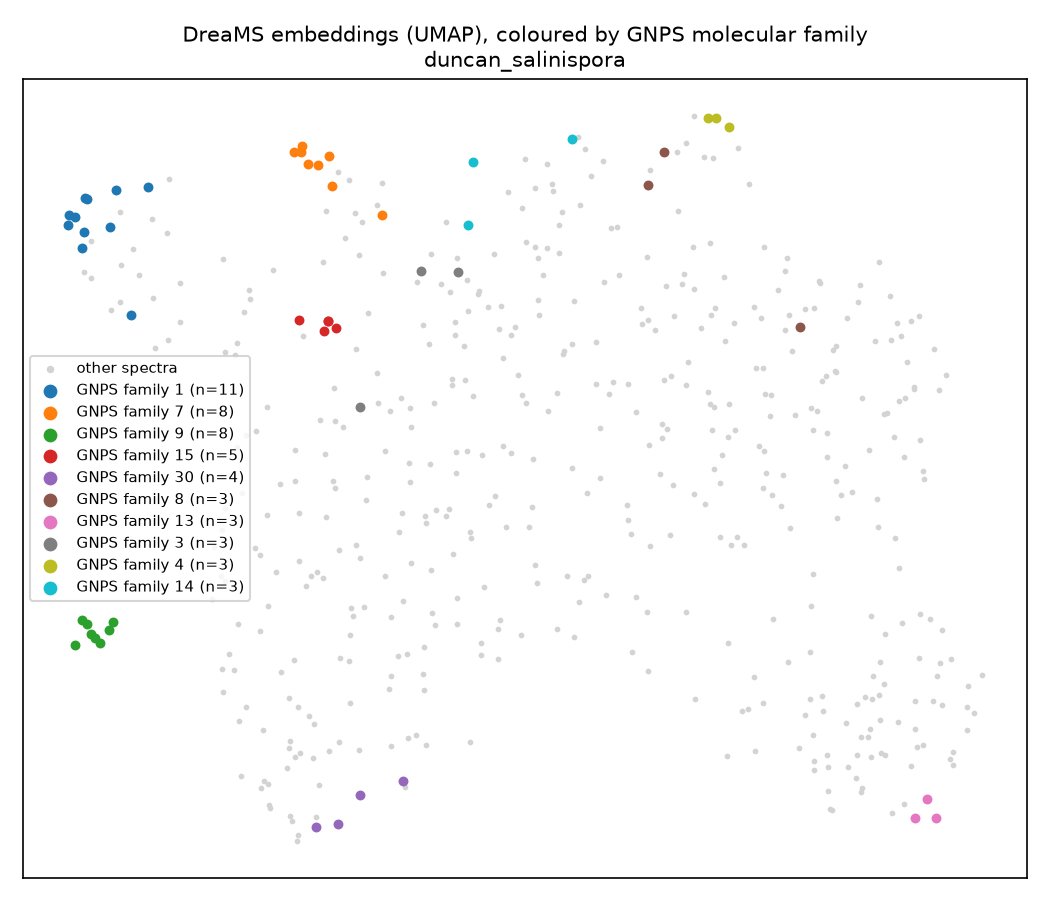

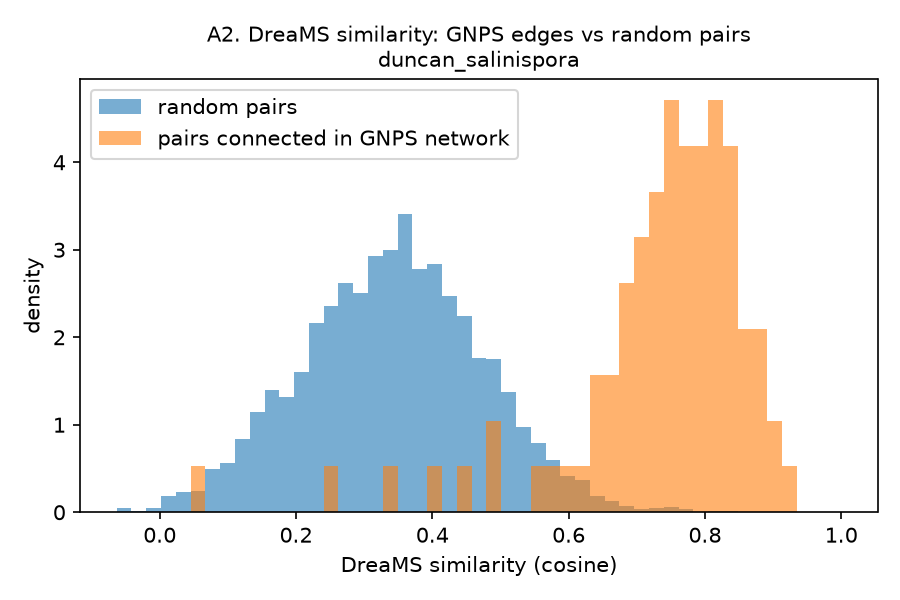

### `crusemann_salstrep` (protocol)

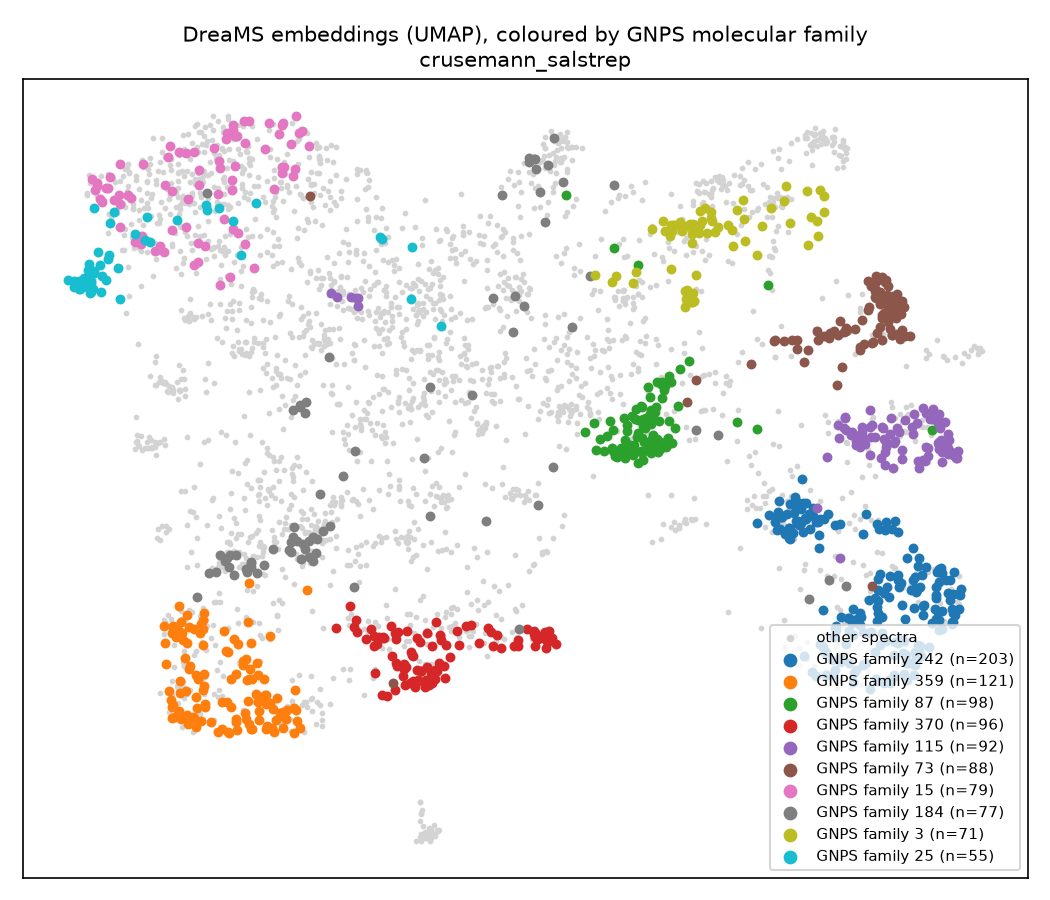

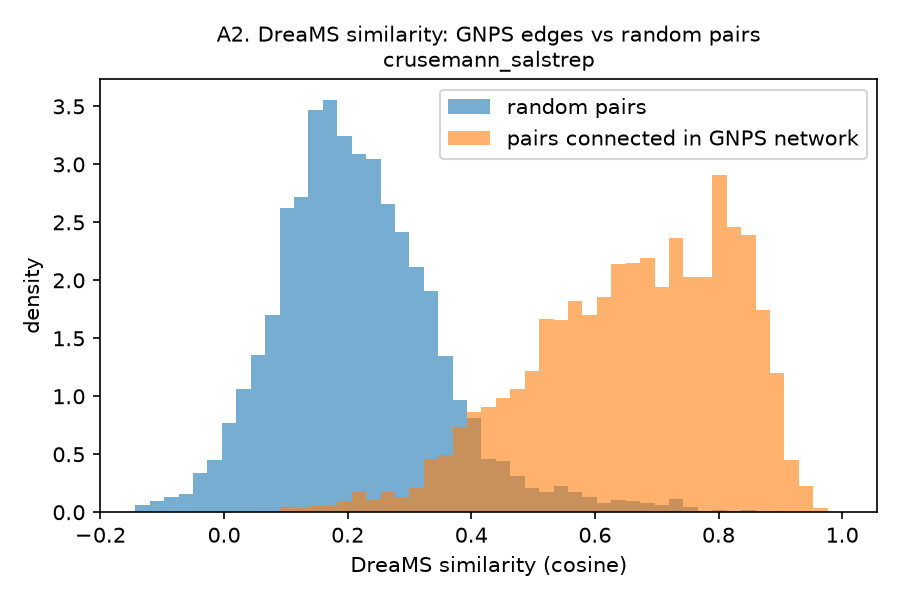

### `chevrette_insect` (protocol)

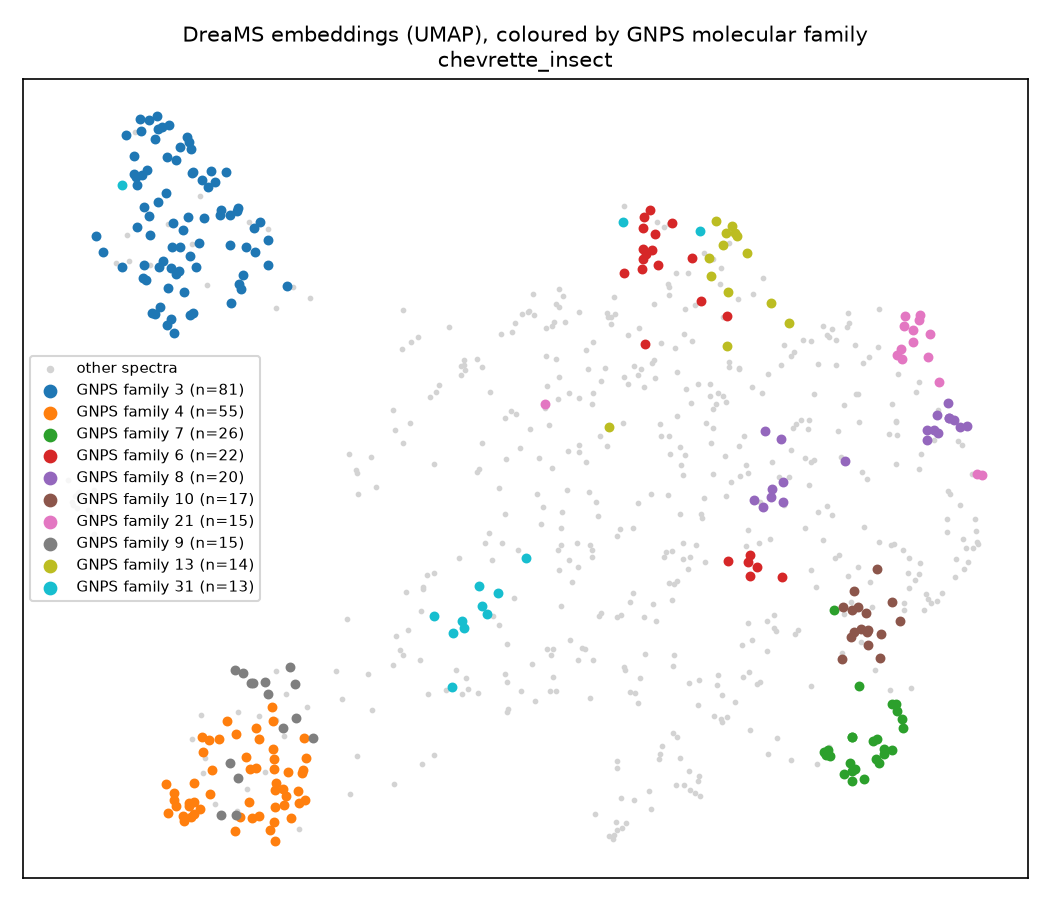

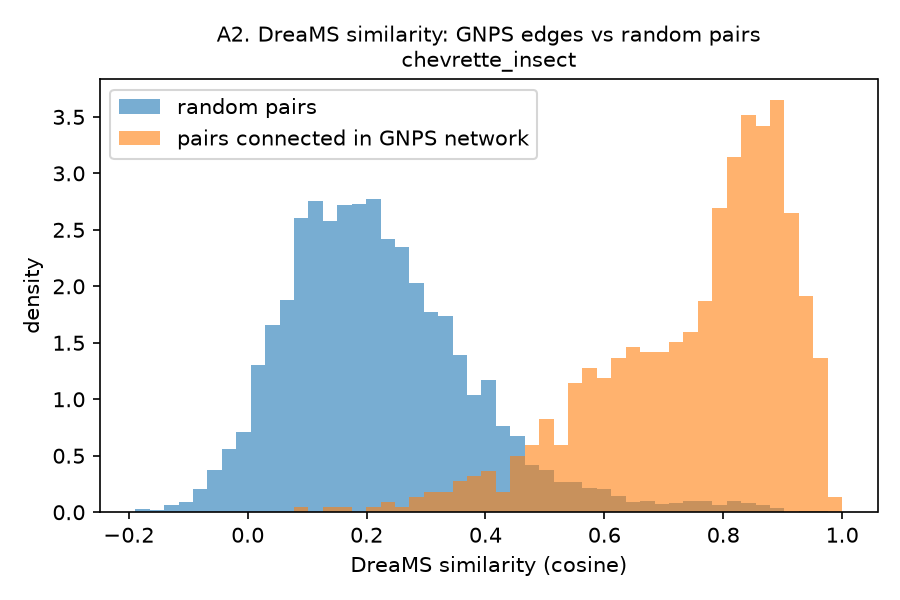

### `dorrestein_salbus` (protocol)

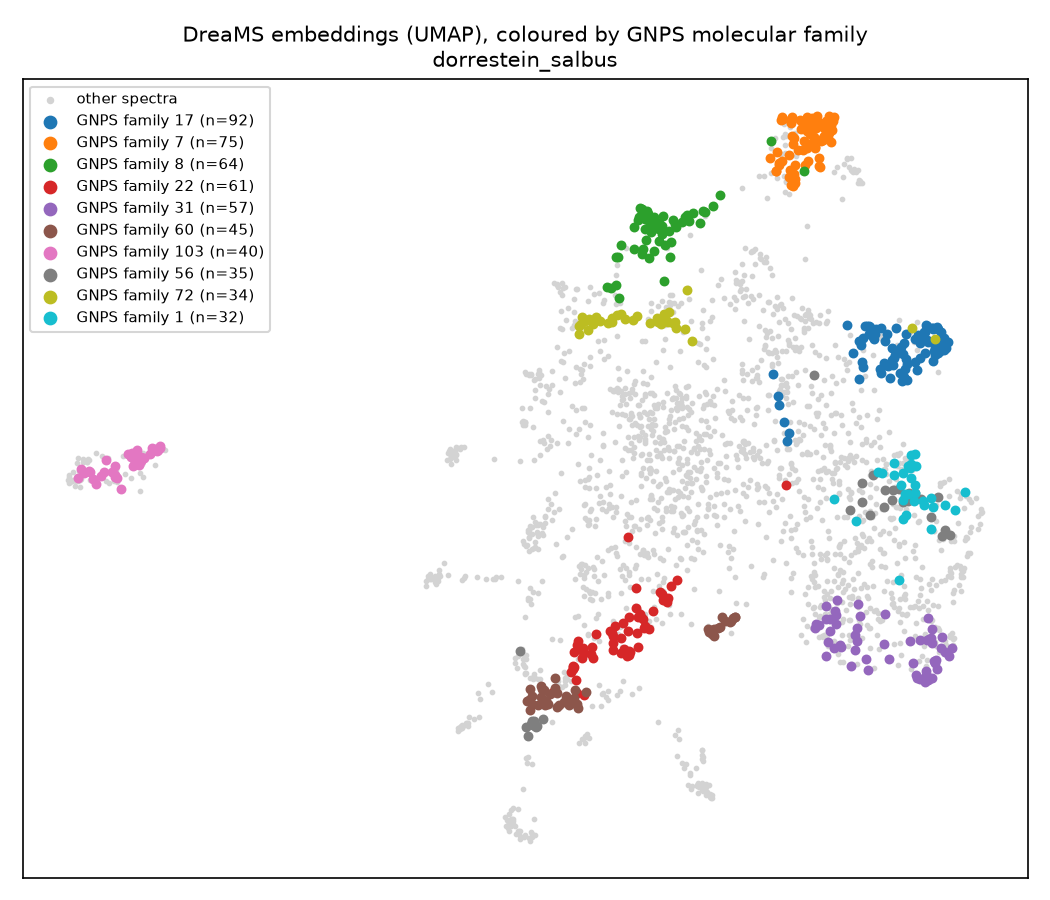

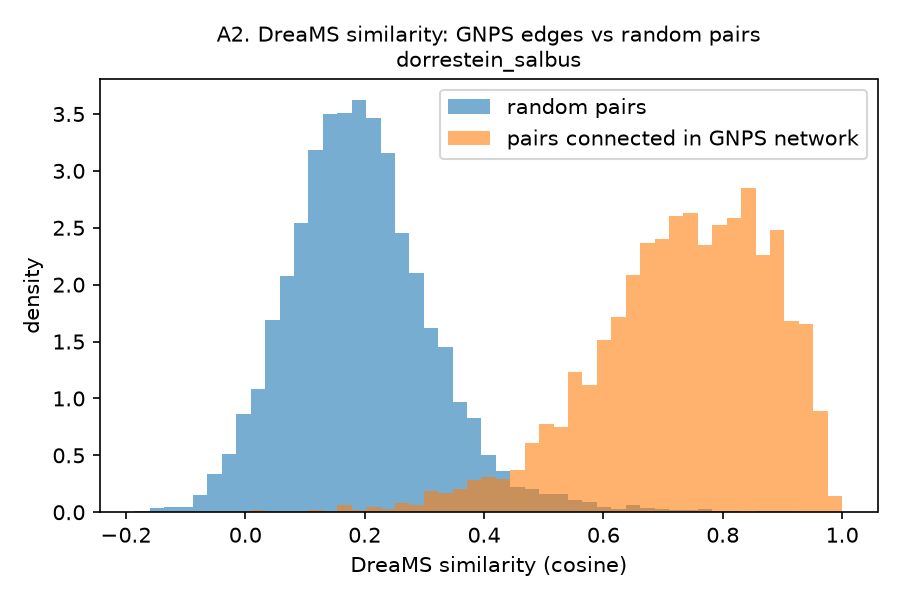

### `tahlan_streptomyces` (protocol)

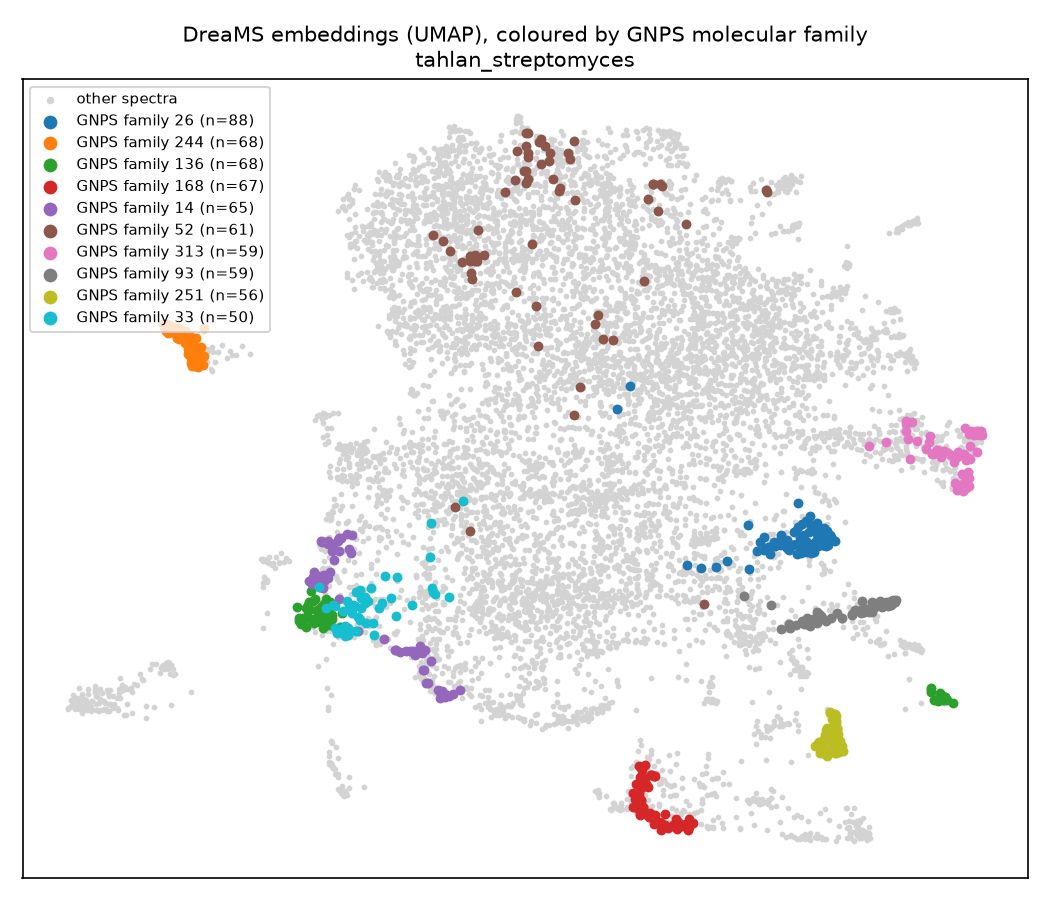

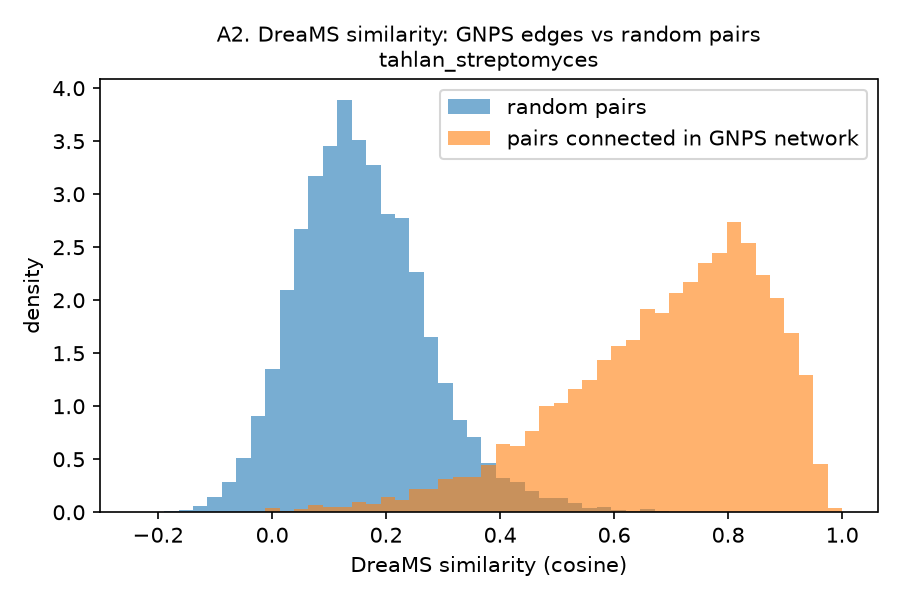

In [6]:
for run in RUNS:
    folder = EXPERIMENT_DIR / "runs" / run / "results"
    if (folder / "exp_a_umap.png").exists():
        display(Markdown(f"### `{run}` (protocol)"))
        display(Image(folder / "exp_a_umap.png", width=560))
        display(Image(folder / "exp_a_similarity_hist.png", width=460))

In [7]:
# DreaMS links that GNPS did not make (first rows). Look at the delta m/z
# (for example +14 = CH2, +16 = O) and at the library names.
for run in RUNS:
    path = EXPERIMENT_DIR / "runs" / run / "results" / "exp_a_new_links.parquet"
    if path.exists():
        display(Markdown(f"**New links: `{run}`**"))
        display(pd.read_parquet(path).head(10))

**New links: `duncan_salinispora`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,159,178,0.879,211.144,211.144,0.0,None,"NCGC00380904-01!1-(3,4-dihydroxy-5-methoxyphenyl)-7-(3,4-dihydroxyphenyl)hep...",involves a GNPS singleton
1,159,196,0.863,211.144,211.144,0.0,None,None,involves a GNPS singleton
2,87,88,0.851,157.084,157.084,0.0,None,Spectral Match to Sebuthylazine from NIST14,involves a GNPS singleton
3,192,196,0.847,211.144,211.144,0.0,HMDB:HMDB00403-614 2-Hydroxyadenine,None,involves a GNPS singleton
4,144,149,0.842,211.144,211.144,0.0,None,None,involves a GNPS singleton
5,178,196,0.840,211.144,211.144,0.0,"NCGC00380904-01!1-(3,4-dihydroxy-5-methoxyphenyl)-7-(3,4-dihydroxyphenyl)hep...",None,involves a GNPS singleton
6,178,192,0.833,211.144,211.144,0.0,"NCGC00380904-01!1-(3,4-dihydroxy-5-methoxyphenyl)-7-(3,4-dihydroxyphenyl)hep...",HMDB:HMDB00403-614 2-Hydroxyadenine,involves a GNPS singleton
7,212,216,0.832,213.149,213.149,0.0,"NCGC00380362-01!1,7-bis(3,4-dihydroxyphenyl)-6-hydroxyheptan-3-one",MLS001148114-01!147-24-0,involves a GNPS singleton
8,145,173,0.829,211.144,211.144,0.0,None,MLS002695961-01!104015-29-4,involves a GNPS singleton
9,136,143,0.828,211.144,211.144,0.0,None,None,involves a GNPS singleton


**New links: `crusemann_salstrep`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,70922,71572,0.945,634.875,634.875,0.000,None,None,involves a GNPS singleton
1,71307,71527,0.942,634.875,634.876,0.001,None,None,involves a GNPS singleton
2,71348,71527,0.940,634.875,634.876,0.001,None,None,involves a GNPS singleton
3,71527,71572,0.935,634.876,634.875,-0.001,None,None,involves a GNPS singleton
4,60635,61001,0.934,566.887,566.888,0.001,None,None,involves a GNPS singleton
5,70922,71310,0.931,634.875,634.875,0.000,None,None,involves a GNPS singleton
6,60641,61001,0.931,566.887,566.888,0.001,None,None,involves a GNPS singleton
7,61001,71649,0.930,566.888,634.876,67.988,None,None,involves a GNPS singleton
8,61001,61745,0.929,566.888,566.891,0.003,None,None,involves a GNPS singleton
9,70922,71527,0.928,634.875,634.876,0.001,None,None,involves a GNPS singleton


**New links: `chevrette_insect`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,1804,1827,0.935,953.741,953.740,-0.001,None,None,involves a GNPS singleton
1,1805,1827,0.927,953.739,953.740,0.001,None,None,involves a GNPS singleton
2,1772,1827,0.926,953.741,953.740,-0.001,None,None,involves a GNPS singleton
3,1772,2024,0.923,953.741,953.743,0.002,None,None,involves a GNPS singleton
4,1186,1248,0.910,697.328,725.346,28.018,None,None,involves a GNPS singleton
5,2039,2381,0.907,953.742,953.744,0.002,None,None,involves a GNPS singleton
6,1745,1767,0.905,953.740,953.743,0.003,None,None,involves a GNPS singleton
7,1758,1781,0.900,953.740,953.740,0.000,None,None,involves a GNPS singleton
8,1756,1772,0.899,953.740,953.741,0.001,None,None,involves a GNPS singleton
9,1772,1869,0.890,953.741,953.744,0.003,None,None,involves a GNPS singleton


**New links: `dorrestein_salbus`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,1162,1164,0.934,287.170,287.200,0.030,None,None,involves a GNPS singleton
1,1220,1221,0.902,293.680,293.690,0.010,None,None,involves a GNPS singleton
2,2965,3486,0.899,519.380,592.430,73.050,None,None,involves a GNPS singleton
3,3111,3497,0.889,539.890,594.670,54.780,None,None,involves a GNPS singleton
4,4072,4148,0.883,678.468,692.481,14.013,None,None,involves a GNPS singleton
5,4461,4489,0.879,821.578,847.590,26.012,None,None,involves a GNPS singleton
6,3429,3736,0.879,586.920,635.190,48.270,None,None,involves a GNPS singleton
7,1750,1753,0.878,347.090,347.100,0.010,None,None,involves a GNPS singleton
8,4470,4489,0.877,831.593,847.590,15.997,None,None,involves a GNPS singleton
9,3051,3429,0.876,529.130,586.920,57.790,None,None,involves a GNPS singleton


**New links: `tahlan_streptomyces`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,24573,24785,0.942,931.700,947.691,15.991,None,None,involves a GNPS singleton
1,23387,23391,0.941,856.441,857.425,0.984,None,None,involves a GNPS singleton
2,21886,23391,0.940,727.398,857.425,130.027,None,None,involves a GNPS singleton
3,19178,23788,0.933,599.503,896.771,297.268,"1,2-Dilinoleoylglycerol",None,involves a GNPS singleton
4,23234,23391,0.932,839.415,857.425,18.010,None,None,involves a GNPS singleton
5,4647,4655,0.930,261.124,261.123,-0.001,"NCGC00384639-01_C14H16N2O3_Pyrrolo[1,2-a]pyrazine-1,4-dione, hexahydro-3-[(4...","NCGC00384639-01_C14H16N2O3_Pyrrolo[1,2-a]pyrazine-1,4-dione, hexahydro-3-[(4...",involves a GNPS singleton
6,4655,4660,0.924,261.123,261.123,0.000,"NCGC00384639-01_C14H16N2O3_Pyrrolo[1,2-a]pyrazine-1,4-dione, hexahydro-3-[(4...","NCGC00384639-01_C14H16N2O3_Pyrrolo[1,2-a]pyrazine-1,4-dione, hexahydro-3-[(4...",involves a GNPS singleton
7,20094,23391,0.924,643.330,857.425,214.095,None,None,involves a GNPS singleton
8,14567,23612,0.923,439.292,877.576,438.284,None,None,involves a GNPS singleton
9,24785,24882,0.923,947.691,961.672,13.981,None,None,involves a GNPS singleton


## 4. Experiment B: chemical structures

Only spectra with a GNPS library hit that has a structure (SMILES). For every pair, the structural similarity of the two molecules (Tanimoto on Morgan fingerprints; also MHFP, Daniel Probst's MinHash fingerprint) is compared with DreaMS, MS2DeepScore, modified cosine (same fragment tolerance as the GNPS job) and binned spectrum cosine.

- **B1.** Spearman correlation over all pairs. The difference between DreaMS and the other methods gets a 95% interval from resampling molecules.
- **B2.** For each spectrum, take its most similar other spectrum and check the Tanimoto of the two molecules. *Analog search* skips spectra of the same molecule.
- A dataset counts for conclusions only with at least 100 different molecules (`B used for conclusions`). We set this rule after the first results, when no method followed the 77 molecules of the Duncan job.

done: exp_b_structures.py --run duncan_salinispora --variant protocol (12 s)


done: exp_b_structures.py --run crusemann_salstrep --variant protocol (8 s)


skipped: exp_b_structures.py --run crusemann_streptomyces --variant protocol: crusemann_streptomyces has no spectra for the 'protocol' variant (none pass the rules, or prepare_data.py has not run).



done: exp_b_structures.py --run chevrette_insect --variant protocol (8 s)


done: exp_b_structures.py --run dorrestein_salbus --variant protocol (8 s)


done: exp_b_structures.py --run tahlan_streptomyces --variant protocol (44 s)


... (3 outputs left out)

done: exp_b_structures.py --run chevrette_insect --variant all_kept (8 s)


done: exp_b_structures.py --run dorrestein_salbus --variant all_kept (8 s)


done: exp_b_structures.py --run tahlan_streptomyces --variant all_kept (43 s)


,duncan_salinispora,crusemann_salstrep,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
metric,,,,,
annotated spectra used,130,21,29,32,420
unique structures,112,16,23,27,324
B used for conclusions,yes,no,no,no,yes
fragment tolerance for modified cosine (Da),0.3,0.5,0.02,0.01,0.02
B1 Spearman (Tanimoto vs DreaMS),0.071,0.024,0.36,0.071,0.229
B1 Spearman (Tanimoto vs MS2DeepScore),0.064,0.161,0.414,0.185,0.261
B1 Spearman (Tanimoto vs modified cosine),0.089,0.097,0.378,0.234,0.259
B1 Spearman (Tanimoto vs binned spectrum cosine),0.071,0.05,0.201,0.19,0.203
B1 Spearman (MHFP vs DreaMS),0.139,0.005,0.462,0.331,0.273


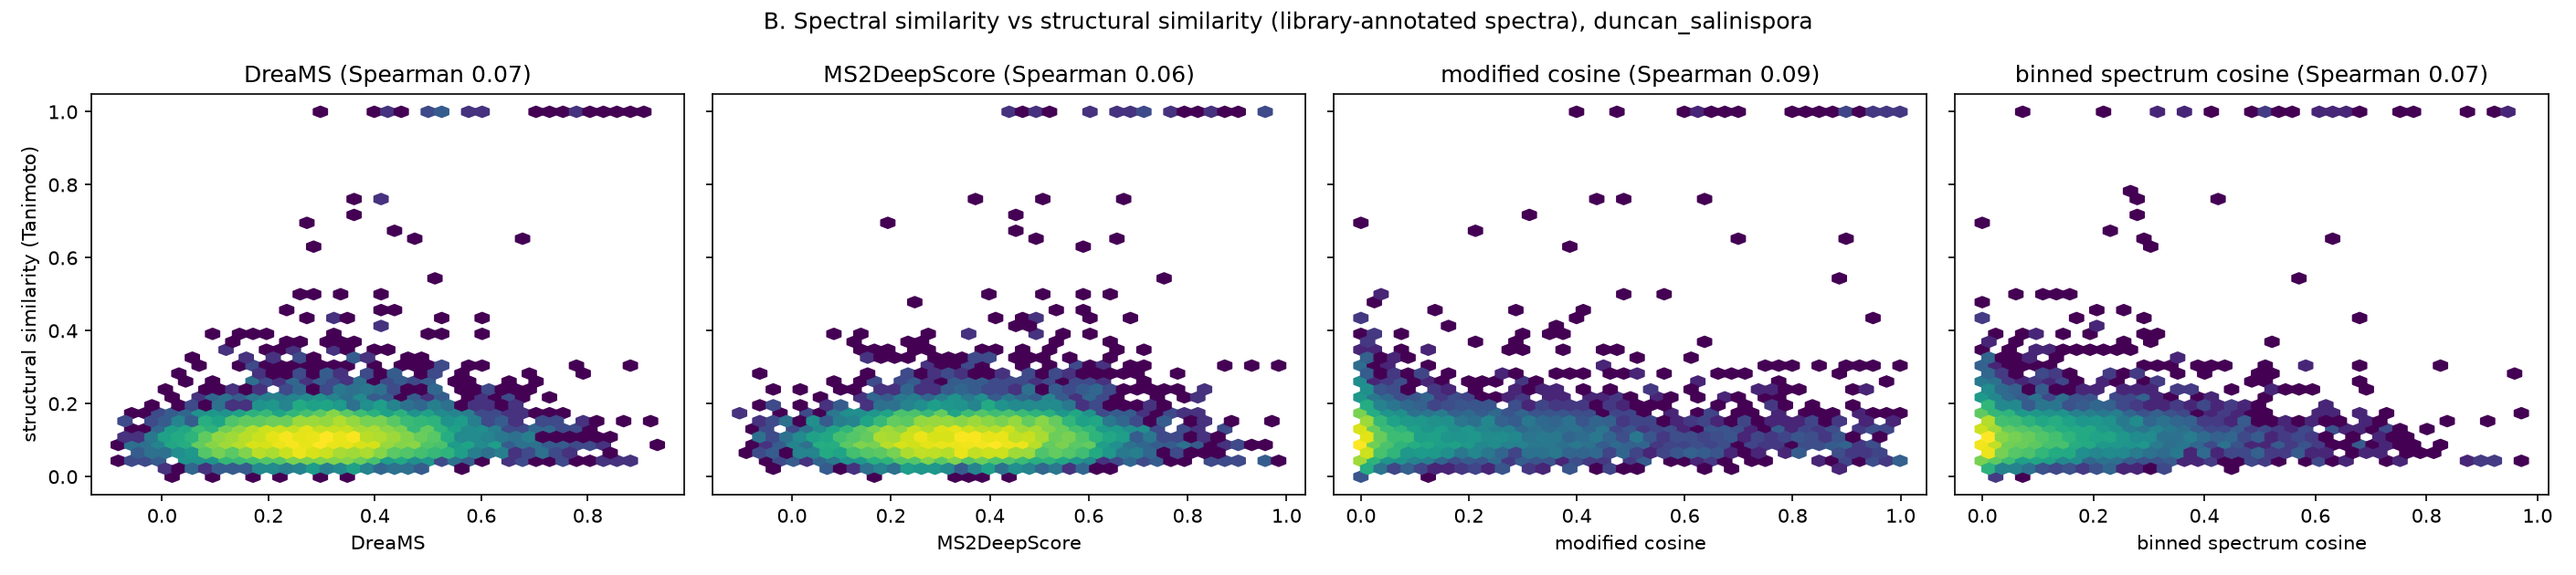

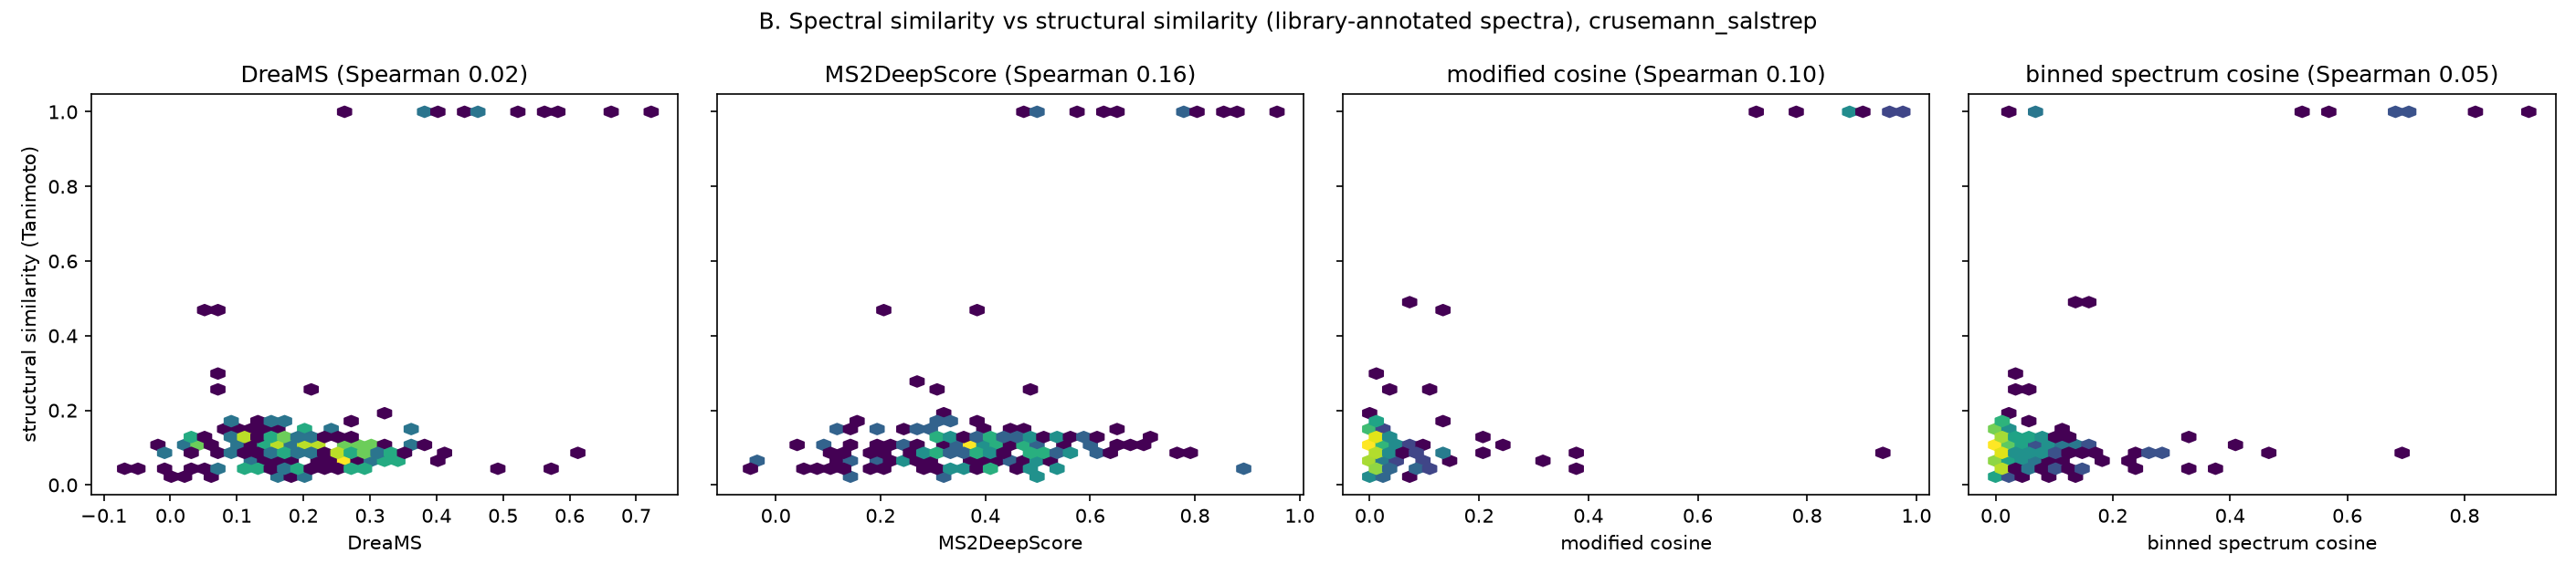

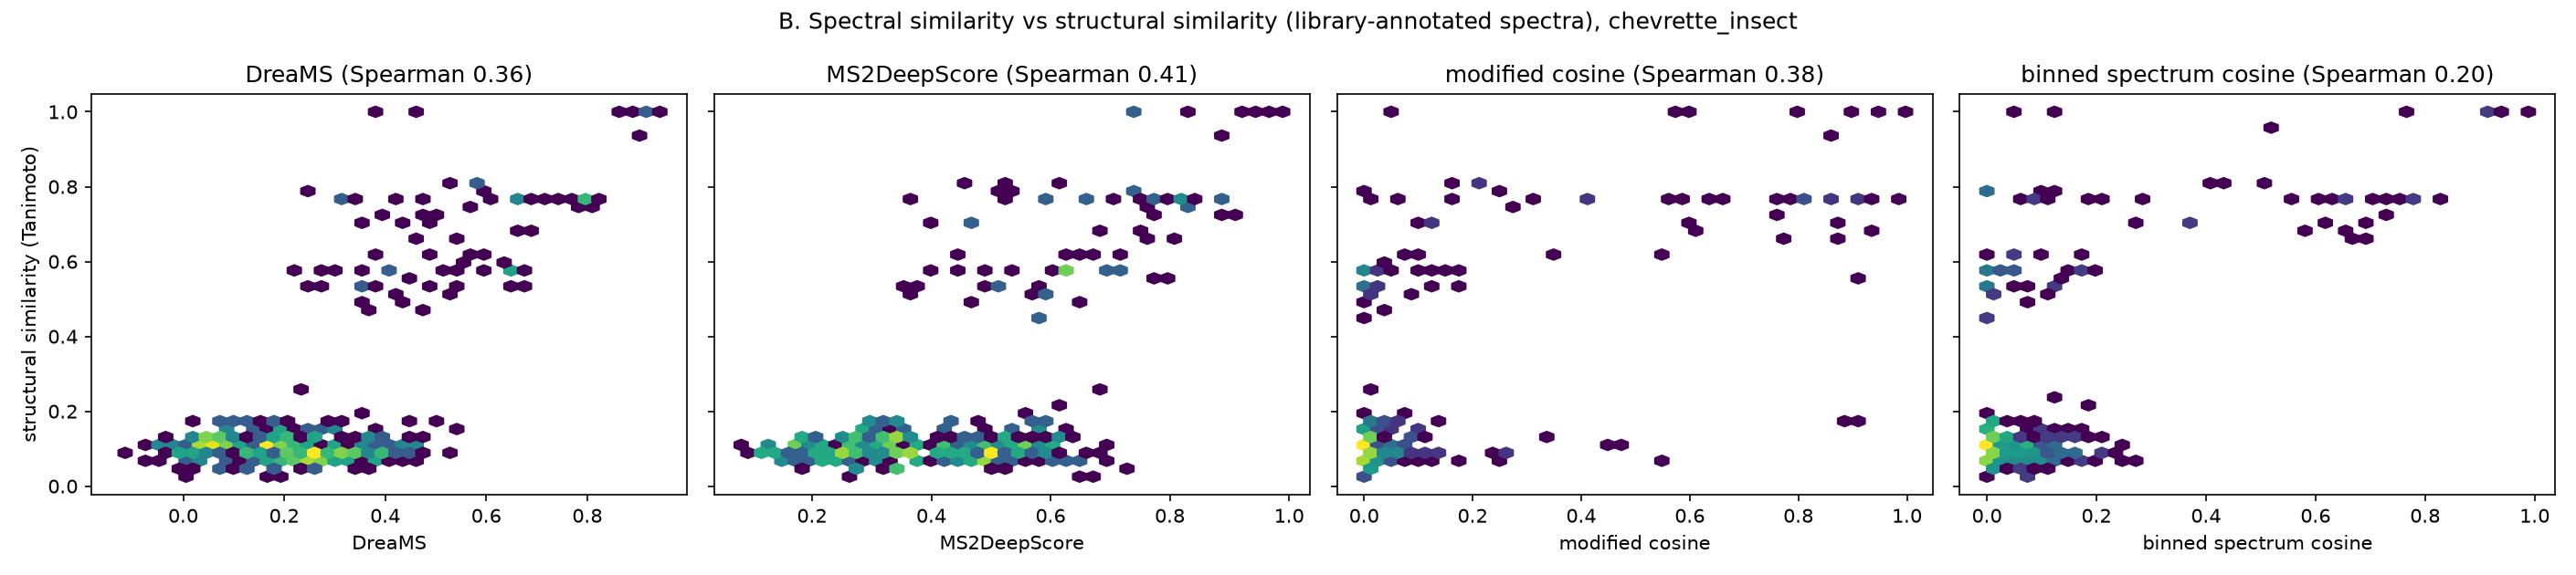

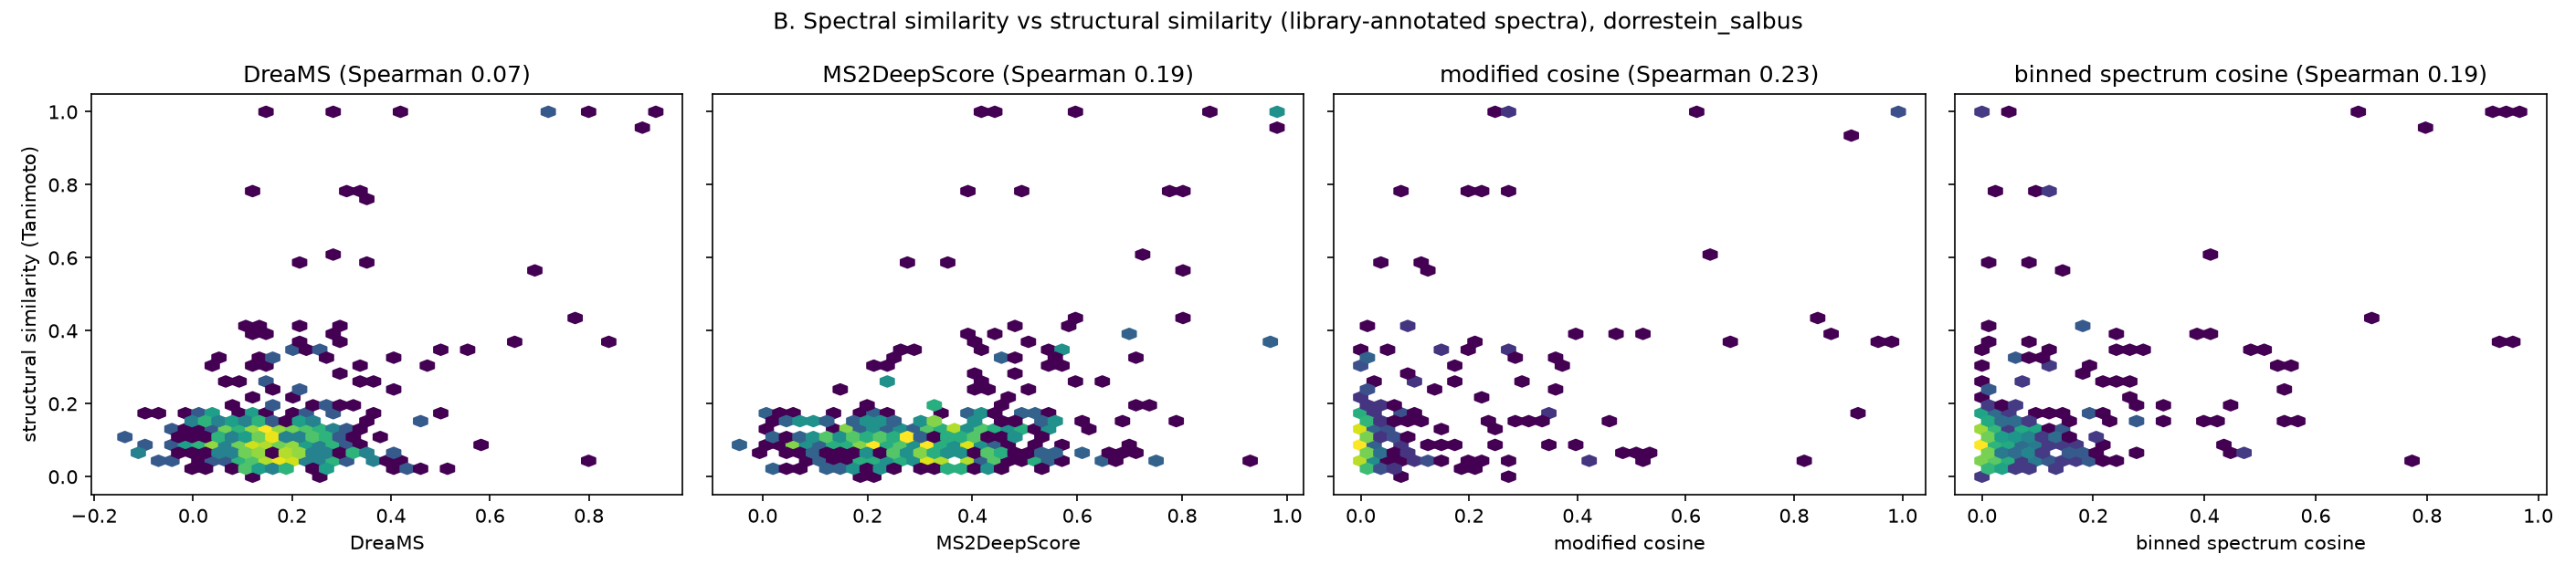

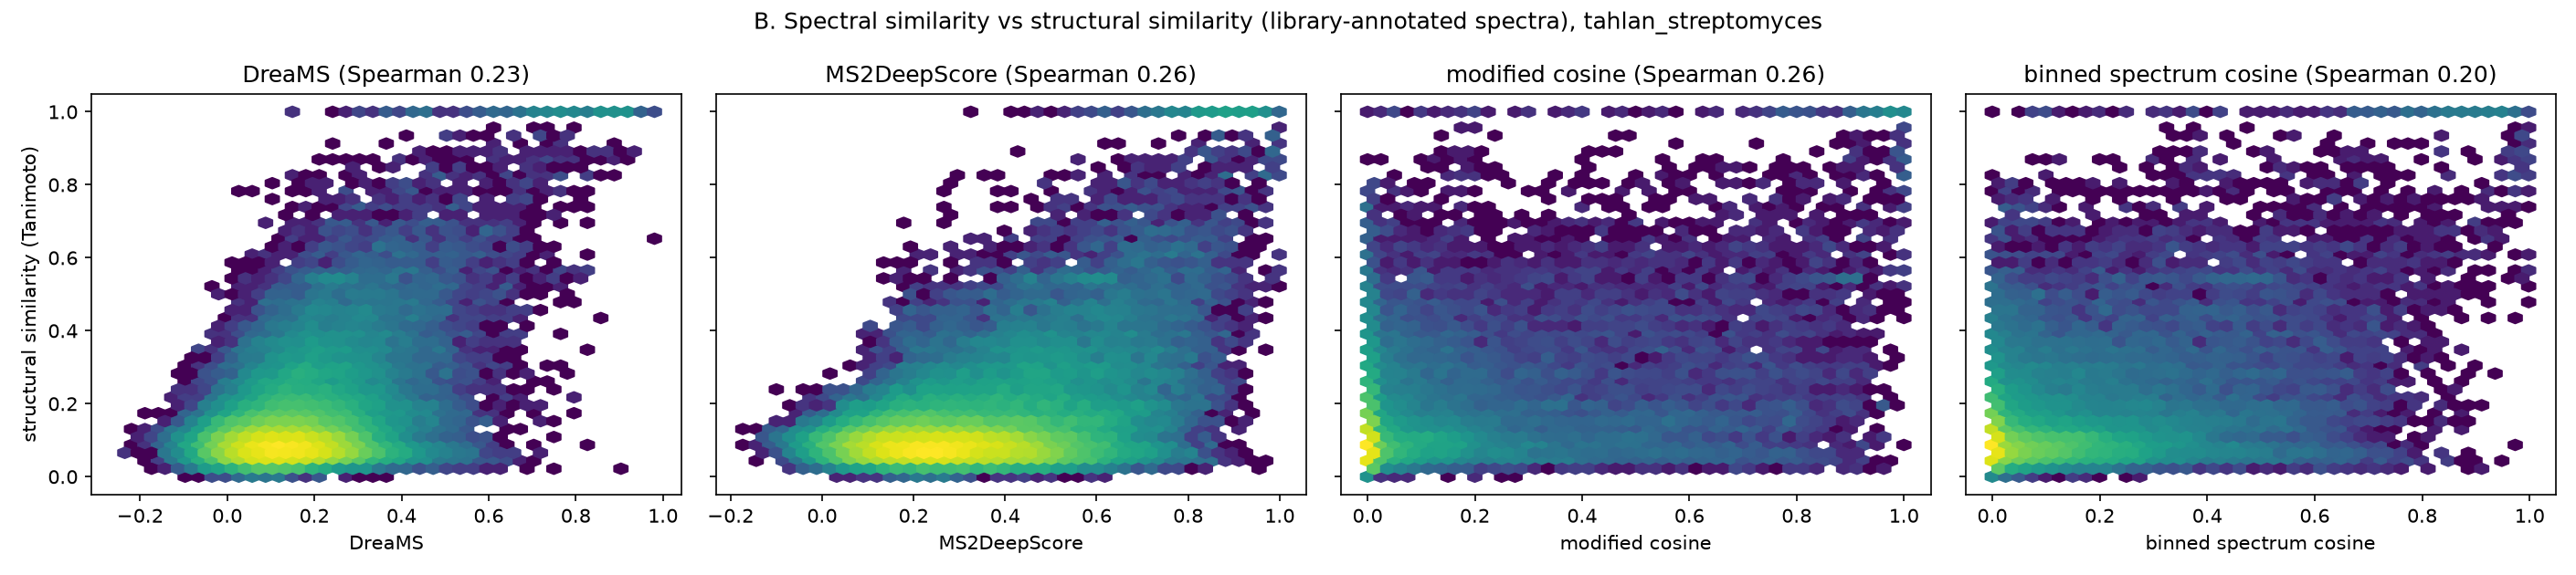

In [8]:
for variant in VARIANTS:
    for run in RUNS:
        step("exp_b_structures.py", "--run", run, "--variant", variant, allow_fail=True)

display(side_by_side("exp_b_summary"))
for run in RUNS:
    figure = EXPERIMENT_DIR / "runs" / run / "results" / "exp_b_structure.png"
    if figure.exists():
        display(Image(figure, width=1000))

## 5. Experiment C (prototype): a small layer trained across labs

Each lab is one client. A linear layer on top of the frozen DreaMS embeddings is trained so that the cosine of two spectra follows the Tanimoto of their molecules (the training target of MS2DeepScore). Compared: pre-trained DreaMS, local training, centralised training (all spectra in one place), a control with only pairs from one lab, FedAvg, and SplitFedV2-like split learning (the server trains on one lab after the other). With DreaMS frozen on the client side, split learning in which the server may pair spectra from different labs is the same as centralised training on the embeddings.

*Performance gap between labs* is the metric of Tirana et al. (AAAI 2026, `my_utils.performance_gap`), over labs instead of labels: 0 = all labs equally well served.

In [9]:
for variant in VARIANTS:
    step("exp_c_federated_adapter.py", "--variant", variant)
display(Markdown((EXPERIMENT_DIR / "federated_prototype" / "RESULTS_federated_prototype.md").read_text(encoding="utf-8")))

done: exp_c_federated_adapter.py --variant protocol (72 s)


done: exp_c_federated_adapter.py --variant all_kept (84 s)


# Experiment C (first prototype): a federated layer on top of frozen DreaMS

*Variant: protocol* (see `common.VARIANTS`).

Generated by `scripts/exp_c_federated_adapter.py`. 3 seeds (mean ± sd). Target: Tanimoto of Morgan fingerprints (radius 2, 2048 bits) of the library-annotated spectra. Test molecules (25% of InChIKeys) are kept apart for all labs. Layer: linear 1024 -> 256; 200 steps for local and centralised, FedAvg 20 rounds x 10 local steps. Settings fixed in advance, not tuned.

## Data per lab

| lab (client) | train spectra | test spectra | train molecules | test molecules |
|---|---|---|---|---|
| duncan_salinispora | 95 | 35 | 82 | 30 |
| crusemann_salstrep | 13 | 8 | 11 | 5 |
| chevrette_insect | 19 | 10 | 17 | 6 |
| dorrestein_salbus | 23 | 9 | 21 | 6 |
| tahlan_streptomyces | 307 | 113 | 245 | 79 |

## Pooled test set (test spectra of all labs)

*Pairs from two labs* uses only pairs of spectra measured in different labs. *Analog search* takes the most similar spectrum of another molecule and reports the Tanimoto of the two molecules. *Performance gap between labs* is the metric of Tirana et al. (AAAI 2026) over labs instead of labels, from each lab's own test spectra (labs with at least 15); 0 = all labs equally well served.

With DreaMS frozen on the client side, split learning in which the server may pair spectra from different labs is the same as *centralised* training on the embeddings: the server sees every lab's embeddings. *SplitFedV2-like* keeps the labs apart and trains on them one after the other.

| method | Spearman, all test pairs | Spearman, pairs from two labs | analog search top-1 Tanimoto | performance gap between labs |
|---|---|---|---|---|
| pre-trained DreaMS (no training) | 0.228 | 0.109 | 0.265 | 0.057 |
| local (mean over labs) | 0.171 ± 0.034 | 0.096 ± 0.034 | 0.243 ± 0.013 |  |
| local (own lab only) |  |  |  | 0.138 ± 0.006 |
| centralised (all spectra in one place) | 0.228 ± 0.015 | 0.114 ± 0.009 | 0.268 ± 0.003 | 0.143 ± 0.013 |
| centralised, pairs within one lab only | 0.230 ± 0.019 | 0.115 ± 0.026 | 0.265 ± 0.003 | 0.147 ± 0.018 |
| federated (FedAvg, spectra stay in the lab) | 0.215 ± 0.015 | 0.100 ± 0.026 | 0.264 ± 0.003 | 0.114 ± 0.010 |
| split learning, labs one after the other (SplitFedV2-like) | 0.210 ± 0.012 | 0.112 ± 0.029 | 0.252 ± 0.007 | 0.129 ± 0.032 |

## Each lab's own test spectra (Spearman with Tanimoto)

Only labs with at least 15 test spectra.

| method | duncan_salinispora | tahlan_streptomyces |
|---|---|---|
| pre-trained DreaMS (no training) | 0.211 | 0.325 |
| local (own lab only) | 0.077 ± 0.008 | 0.354 ± 0.006 |
| centralised (all spectra in one place) | 0.055 ± 0.003 | 0.341 ± 0.024 |
| centralised, pairs within one lab only | 0.050 ± 0.048 | 0.343 ± 0.015 |
| federated (FedAvg, spectra stay in the lab) | 0.098 ± 0.023 | 0.326 ± 0.003 |
| split learning, labs one after the other (SplitFedV2-like) | 0.041 ± 0.055 | 0.299 ± 0.010 |

## Limitations

- Library hits are putative annotations, so the target is noisy.
- The DreaMS embedding model was fine-tuned on public library spectra; some of these molecules may be among them, which favours the pre-trained model.
- Few annotated spectra in most labs; the per-lab numbers are uncertain.
- FedAvg is simulated on one machine, without communication cost or privacy measures.


## 6. Experiment D: how different are the labs?

A federated study needs a measured heterogeneity. Can a logistic regression tell two labs apart from their embeddings? Balanced accuracy 0.5 = the labs look the same, 1.0 = fully separated. Labs differ in chemistry and in measurement at the same time; the test on molecules that both labs measured holds the chemistry fixed.

In [10]:
step("exp_d_lab_shift.py")
display(Markdown((EXPERIMENT_DIR / "lab_shift" / "RESULTS_lab_shift_protocol.md").read_text(encoding="utf-8")))

done: exp_d_lab_shift.py  (11 s)


# Experiment D: how different are the labs?

Generated by `scripts/exp_d_lab_shift.py`, variant `protocol`. Logistic regression, 5-fold cross-validation, the same number of spectra from both labs (at most 1500). Balanced accuracy 0.5 = the two labs look the same, 1.0 = fully separated. *Shared molecules* repeats the test on library-annotated spectra of molecules measured in both labs (only when each lab has at least 10 of them), so that chemistry is held fixed.

| lab A | lab B | representation | all spectra: balanced accuracy | spectra per lab | shared molecules | shared molecules: balanced accuracy | shared: spectra per lab |
|---|---|---|---|---|---|---|---|
| duncan_salinispora | crusemann_salstrep | DreaMS | 0.975 | 528 | 0 |  |  |
| duncan_salinispora | crusemann_salstrep | binned spectrum | 0.98 | 528 | 0 |  |  |
| duncan_salinispora | crusemann_salstrep | MS2DeepScore | 0.928 | 528 | 0 |  |  |
| duncan_salinispora | chevrette_insect | DreaMS | 0.966 | 528 | 0 |  |  |
| duncan_salinispora | chevrette_insect | binned spectrum | 0.987 | 528 | 0 |  |  |
| duncan_salinispora | chevrette_insect | MS2DeepScore | 0.911 | 528 | 0 |  |  |
| duncan_salinispora | dorrestein_salbus | DreaMS | 0.974 | 528 | 1 |  |  |
| duncan_salinispora | dorrestein_salbus | binned spectrum | 0.968 | 528 | 1 |  |  |
| duncan_salinispora | dorrestein_salbus | MS2DeepScore | 0.894 | 528 | 1 |  |  |
| duncan_salinispora | tahlan_streptomyces | DreaMS | 0.978 | 528 | 3 |  |  |
| duncan_salinispora | tahlan_streptomyces | binned spectrum | 0.978 | 528 | 3 |  |  |
| duncan_salinispora | tahlan_streptomyces | MS2DeepScore | 0.903 | 528 | 3 |  |  |
| crusemann_salstrep | chevrette_insect | DreaMS | 0.913 | 785 | 2 |  |  |
| crusemann_salstrep | chevrette_insect | binned spectrum | 0.931 | 785 | 2 |  |  |
| crusemann_salstrep | chevrette_insect | MS2DeepScore | 0.851 | 785 | 2 |  |  |
| crusemann_salstrep | dorrestein_salbus | DreaMS | 0.913 | 1500 | 1 |  |  |
| crusemann_salstrep | dorrestein_salbus | binned spectrum | 0.924 | 1500 | 1 |  |  |
| crusemann_salstrep | dorrestein_salbus | MS2DeepScore | 0.852 | 1500 | 1 |  |  |
| crusemann_salstrep | tahlan_streptomyces | DreaMS | 0.919 | 1500 | 2 |  |  |
| crusemann_salstrep | tahlan_streptomyces | binned spectrum | 0.914 | 1500 | 2 |  |  |
| crusemann_salstrep | tahlan_streptomyces | MS2DeepScore | 0.824 | 1500 | 2 |  |  |
| chevrette_insect | dorrestein_salbus | DreaMS | 0.92 | 785 | 3 |  |  |
| chevrette_insect | dorrestein_salbus | binned spectrum | 0.959 | 785 | 3 |  |  |
| chevrette_insect | dorrestein_salbus | MS2DeepScore | 0.87 | 785 | 3 |  |  |
| chevrette_insect | tahlan_streptomyces | DreaMS | 0.955 | 785 | 7 |  |  |
| chevrette_insect | tahlan_streptomyces | binned spectrum | 0.976 | 785 | 7 |  |  |
| chevrette_insect | tahlan_streptomyces | MS2DeepScore | 0.889 | 785 | 7 |  |  |
| dorrestein_salbus | tahlan_streptomyces | DreaMS | 0.845 | 1500 | 12 | 0.433 | 13.0 |
| dorrestein_salbus | tahlan_streptomyces | binned spectrum | 0.865 | 1500 | 12 | 0.383 | 13.0 |
| dorrestein_salbus | tahlan_streptomyces | MS2DeepScore | 0.754 | 1500 | 12 | 0.2 | 13.0 |

Labs differ in chemistry and in measurement at the same time, so a high accuracy on all spectra alone does not show an instrument effect. Library annotations are putative.


## 7. Could DreaMS be tested for genome-metabolome linking?

NPLinker-style linking connects molecular families to gene cluster families through their presence across strains, and is judged on known BGC-spectrum links. A fair test of DreaMS for this needs many strains with genomes, known links, and spectra that DreaMS accepts.

In [11]:
step("linking_feasibility.py")
display(Markdown((EXPERIMENT_DIR / "linking_feasibility" / "RESULTS_linking_feasibility.md").read_text(encoding="utf-8")))

done: linking_feasibility.py  (20 s)


# Can DreaMS be tested for genome-metabolome linking with public data?

Generated by `scripts/linking_feasibility.py` from the GNPS jobs of the actinobacterial PoDP datasets on this laptop and `data/derived/podp_projects.csv`. *Usable* means at least 10 genomes (strain variation for correlation-based linking), at least 3 known BGC-MS2 links and at least 50% of the spectra accepted by DreaMS's own format A check. These thresholds are our choice.

| MassIVE | GNPS task | PI | genomes | known BGC-MS2 links | fragment tolerance (Da) | spectra with peaks | pass DreaMS's own check | share | usable for a linking test |
|---|---|---|---|---|---|---|---|---|---|
| MSV000078836 | 9360fa51 | Max Crüsemann | 120 | 9 | 0.5 | 6246 | 3445 | 55% | yes |
| MSV000084771 | a50dc9e2 | Leonard Kaysser, Nadine Ziemert | 11 | 9 | 0.04 | 11464 | 319 | 3% | no |
| MSV000083648 | e76dfbd2 | Neil Kelleher | 3 | 7 | 0.02 | 1323 | 175 | 13% | no |
| MSV000083835 | 8943515e | Kapil Tahlan | 4 | 6 | 0.5 | 3281 | 2444 | 74% | no |
| MSV000083835 | b5eb3498 | Kapil Tahlan | 4 | 6 | 0.02 | 12719 | 8901 | 70% | no |
| MSV000078839 | 840eadb0 | Ellis O'Neill | 39 | 5 | 0.5 | 2834 | 0 | 0% | no |
| MSV000079519 | 7e463ca8 | Pieter C. Dorrestein | 1 | 5 | 0.01 | 4707 | 2392 | 51% | no |
| MSV000079284 | c22f44b1 | Dr. Katherine Duncan | 28 | 2 | 0.3 | 25935 | 528 | 2% | no |
| MSV000082988 | 8fd1fcfa | Gilles P. van Wezel | 1 | 1 | 0.5 | 183 | 101 | 55% | no |
| MSV000083081 | 24d515f7 | Bradley Moore | 1 | 1 | 0.5 | 1080 | 0 | 0% | no |
| MSV000087784 | 78cfa392 | Gilles van Wezel | 1 | 1 | 0.02 | 285 | 224 | 79% | no |
| MSV000084723 | 927974dc | Cameron Currie & Tim Bugni | 120 | 0 | 0.02 | 1214 | 785 | 65% | no |
| MSV000084989 | 471d8f87 | Ki Hyun Kim | 1 | 0 | 0.5 | 169 | 29 | 17% | no |

## Known links of the usable dataset: can DreaMS see the molecules?

Library-annotated spectra of each linked molecule, and how many pass DreaMS's own check. Format A accepts only charge +1 and precursor m/z up to 1000, so large or doubly charged molecules are out of the DreaMS domain.

| MassIVE | known link | annotated spectra | pass DreaMS's own check | precursor m/z |
|---|---|---|---|---|
| MSV000078836 | staurosporine (BGC0000827) | 10 | 10 | 466, 467, 482, 483 |
| MSV000078836 | cyclomarin (BGC0000333) | 2 | 0 | 1026, 1036 |
| MSV000078836 | desferrioxamine (BGC0000940) | 6 | 6 | 561, 601, 623, 730, 758 |
| MSV000078836 | lomaiviticin (BGC0000241) | 3 | 0 | 670, 677, 684 |
| MSV000078836 | retimycin (BGC0001228) | 1 | 0 | 1171 |
| MSV000078836 | rifamycin S and W (BGC0000137, two links) | 3 | 2 | 656, 696, 718 |
| MSV000078836 | rosamicin (BGC0001830) | 7 | 3 | 582, 583, 598, 600 |
| MSV000078836 | arenimycin (BGC0000198) | 3 | 3 | 668, 809 |


## 8. All results in one page, and automatic checks

`scripts/report.py` writes `RESULTS.md`. `scripts/check_pipeline.py` runs unit checks, checks that every file matches its spectra, and compares the summaries with the saved reference in `tests/reference/`.

In [12]:
step("report.py", "--runs", *RUNS)
step("check_pipeline.py", show=True)

done: report.py --runs duncan_salinispora crusemann_salstrep crusemann_streptomyces chevrette_insect dorrestein_salbus tahlan_streptomyces (1 s)


ok    GNPS check accepts consistent files
ok    GNPS check catches an extra node
ok    GNPS check catches an edge to an unknown node
ok    GNPS check catches a library hit on an unknown node
ok    bootstrap interval of a constant is the constant
ok    resampling whole groups gives a wider interval
ok    duncan_salinispora (protocol): metadata and MGF have the same number of spectra
ok    duncan_salinispora (protocol): one DreaMS embedding per spectrum
ok    duncan_salinispora (protocol): DreaMS embeddings belong to this MGF file
ok    duncan_salinispora (protocol): one MS2DeepScore embedding per spectrum
ok    duncan_salinispora (protocol): MS2DeepScore embeddings belong to this MGF file
ok    duncan_salinispora (protocol): every spectrum passes DreaMS's own check
ok    duncan_salinispora (all_kept): metadata and MGF have the same number of spectra
ok    duncan_salinispora (all_kept): one DreaMS embedding per spectrum
ok    duncan_salinispora (all_kept): DreaMS embeddings belong to thi

## 9. How to read the results

Write your own interpretation here before the meeting. Some guiding questions:
- Does our setup reproduce the DreaMS tutorial (section 0b)? If not, nothing below can be trusted yet.
- In A1, do the 95% intervals of *DreaMS minus binned cosine* and *DreaMS minus MS2DeepScore* contain 0? Is it the same in all datasets?
- In B, which datasets count for conclusions? There, is DreaMS better than modified cosine and MS2DeepScore, or not detectably different?
- How do the `protocol` and `all_kept` results differ, especially for Duncan?
- In C, does any trained layer beat pre-trained DreaMS on pairs from two labs? Is there a performance gap between labs?
- In D, are the labs different only in chemistry, or also in measurement?
- Which public dataset, if any, could test DreaMS for linking?

**My interpretation:** *(write here)*

## 10. Limitations

1. **GNPS families are not ground truth.** They come from modified cosine, so Experiment A measures agreement with GNPS.
2. **Library hits are putative.** They are spectral matches, not confirmed structures. Only datasets with at least 100 different molecules count for conclusions in Experiment B.
3. **Consensus spectra.** GNPS gives clustered (consensus) spectra; DreaMS was trained on single scans. The `protocol` variant follows DreaMS's quality rules but still uses consensus spectra.
4. **Possible overlap with training data.** These datasets are public on MassIVE, so they may be part of GeMS (DreaMS pre-training, without labels). The DreaMS embedding model and MS2DeepScore were trained on public library spectra with known structures; the library spectra behind our annotations may be among them, which can favour both models in Experiment B.
5. **The runs are not independent.** The SalStrep job also re-analyses the *Streptomyces* data of MSV000078839.
6. **Small numbers.** Few annotated spectra in most datasets; in Experiment C one lab has most of the training spectra.
7. **Experiments C and D are prototypes**, simulated on one machine, with settings fixed in advance and not tuned.

## 11. Open questions

**For Joana and Daniel**
1. What did "train" mean in our meeting: fine-tuning DreaMS, training a new model, or federated training?
2. Partner spectra will mostly have no annotation. Should a federated version be self-supervised (like DreaMS pre-training)? That needs a GPU: is there a WUR server I can use?
3. Is there a high-resolution actinobacteria dataset in PRIORITY with many strains and known links, so that DreaMS can be tested for linking?
4. Is the data-quality finding (the first "difference between labs" was out-of-domain data) interesting for federated learning, for example as a check before a client joins?